<a href="https://colab.research.google.com/github/arxsyy/MachineLearning_2026/blob/main/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

menggunakan dataset Iris.csv

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import hdbscan

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

In [5]:
# 1. Membaca Dataset Iris

df = pd.read_csv('Iris.csv')

# Menampilkan 5 data pertama
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
# Memeriksa Informasi Dataset

print("Ukuran Dataset:", df.shape)

print("\nInformasi Dataset:")
df.info()

print("\nMissing Value:")
print(df.isnull().sum())

print("\nDistribusi Species:")
print(df['Species'].value_counts())

Ukuran Dataset: (150, 6)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Missing Value:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Distribusi Species:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [7]:
# Memilih Fitur untuk Clustering

features = [
    'SepalLengthCm',
    'SepalWidthCm',
    'PetalLengthCm',
    'PetalWidthCm'
]

X = df[features]

# Menyimpan label asli untuk evaluasi
y_true = df['Species']

X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [8]:
# Melakukan Standardisasi Data

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Ukuran Data Setelah Standardisasi:", X_scaled.shape)
print("\n5 Data Pertama:")
print(X_scaled[:5])

Ukuran Data Setelah Standardisasi: (150, 4)

5 Data Pertama:
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


2. Melakukan clustering dengan HDBSCAN

In [9]:
# 2. Membuat Model HDBSCAN

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

labels = clusterer.fit_predict(X_scaled)

# Menambahkan hasil cluster ke dataset
df['Cluster'] = labels

print("Hasil Clustering:")
print(df[['Species', 'Cluster']].head(10))

Hasil Clustering:
       Species  Cluster
0  Iris-setosa        1
1  Iris-setosa        1
2  Iris-setosa        1
3  Iris-setosa        1
4  Iris-setosa        1
5  Iris-setosa        1
6  Iris-setosa        1
7  Iris-setosa        1
8  Iris-setosa        1
9  Iris-setosa        1


In [10]:
# Menghitung Jumlah Cluster dan Noise

jumlah_cluster = len(set(labels)) - (1 if -1 in labels else 0)
jumlah_noise = np.sum(labels == -1)

print("Jumlah Cluster:", jumlah_cluster)
print("Jumlah Noise:", jumlah_noise)
print("Jumlah Data:", len(labels))

print("\nJumlah Anggota Setiap Cluster:")
print(df['Cluster'].value_counts().sort_index())

Jumlah Cluster: 2
Jumlah Noise: 2
Jumlah Data: 150

Jumlah Anggota Setiap Cluster:
Cluster
-1     2
 0    99
 1    49
Name: count, dtype: int64


3. Melaporkan hasil clustering

In [11]:
# 3. Melakukan Reduksi Dimensi dengan PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Variance yang Dijelaskan:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance:")
print(sum(pca.explained_variance_ratio_))

Variance yang Dijelaskan:
[0.72770452 0.23030523]

Total Variance:
0.9580097536148199


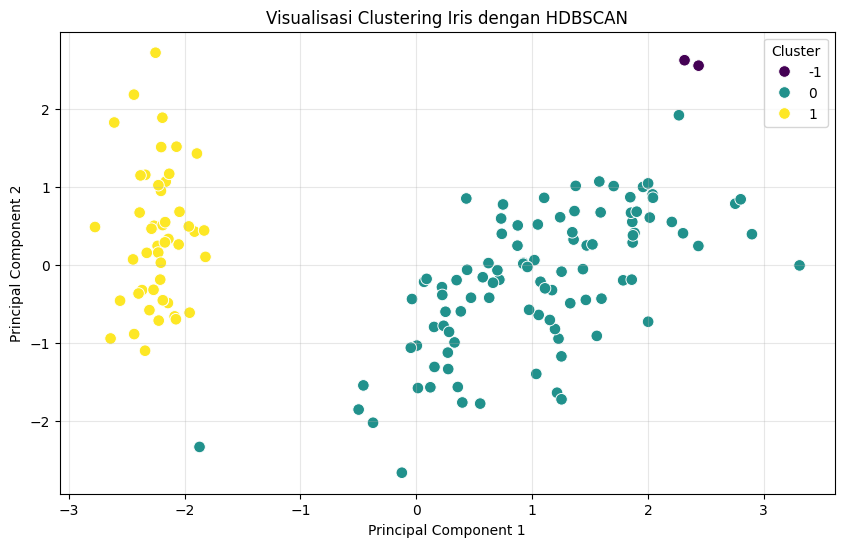

In [12]:
# Visualisasi Hasil Clustering HDBSCAN

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=labels,
    palette='viridis',
    s=70
)

plt.title('Visualisasi Clustering Iris dengan HDBSCAN')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

4. Analisis kesesuaian hasil clustering dengan label asli

In [13]:
# 4. Evaluasi Kesesuaian Cluster dengan Label Asli

ari_score = adjusted_rand_score(y_true, labels)

print("Adjusted Rand Index (ARI):", round(ari_score, 4))

Adjusted Rand Index (ARI): 0.5394


In [14]:
# Membuat Tabel Perbandingan Species dan Cluster

comparison = pd.crosstab(
    df['Species'],
    df['Cluster'],
    rownames=['Species Asli'],
    colnames=['Hasil Cluster']
)

comparison

Hasil Cluster,-1,0,1
Species Asli,,,
Iris-setosa,0,1,49
Iris-versicolor,0,50,0
Iris-virginica,2,48,0


In [15]:
# Menghitung Silhouette Score

mask = labels != -1

if len(set(labels[mask])) >= 2:
    sil_score = silhouette_score(
        X_scaled[mask],
        labels[mask]
    )
    print("Silhouette Score:", round(sil_score, 4))
else:
    print("Silhouette Score tidak dapat dihitung karena cluster kurang dari 2.")

Silhouette Score: 0.5836


Berdasarkan hasil clustering menggunakan algoritma HDBSCAN pada dataset Iris dengan 150 data, diperoleh 2 cluster dan 2 data noise. Visualisasi menggunakan PCA menunjukkan bahwa kedua cluster memiliki persebaran yang cukup jelas. Hasil evaluasi memperoleh nilai Silhouette Score sebesar 0,5836, yang menunjukkan kualitas pengelompokan cukup baik. Namun, hasil clustering belum sepenuhnya sesuai dengan label asli dataset Iris yang memiliki 3 spesies, karena HDBSCAN mengelompokkan data berdasarkan kepadatan, bukan berdasarkan label spesies.